Objectives.

This notebook examines sales performance and demand variability at the individual product (SKU) level.
The analysis aims to identify products that contribute significantly to total sales value and assess differences in demand stability across products.

Key Areas of Analysis

1.SKU-level sales performance.

2.ABC classification based on cumulative sales value.

3.XYZ classification based on demand variability.

4.Combined ABC-XYZ inventory segmentation.

5.Implications for demand forecasting and inventory management.

The findings will support the identification of priority products and inform subsequent forecasting and inventory planning decisions.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the cleaned FMCG dataset
df = pd.read_csv(
    "../data/fmcg_sales_cleaned.csv",
    parse_dates=["date"]
)

# Confirm dataset dimensions
df.shape

(1100000, 33)

In [3]:
# Count the number of unique products
total_skus = df['sku_id'].nunique()

print(f"Total unique SKUs: {total_skus}")

Total unique SKUs: 102


In [4]:
# Aggregate sales performance for each SKU
sku_sales = (
    df.groupby('sku_id')
    .agg(
        total_units_sold=('units_sold', 'sum'),
        total_net_sales=('net_sales', 'sum')
    )
    .reset_index()
)

In [5]:
# Sort products by total net sales
sku_sales = sku_sales.sort_values(
    by='total_net_sales',
    ascending=False
)

In [6]:
# Display the top 10 products
sku_sales.head(10)

,sku_id,total_units_sold,total_net_sales
17,SKU0018,1173032,17032424.64
26,SKU0027,1200897,16000295.02
25,SKU0026,893989,13025419.73
98,SKU0099,1242389,12968809.43
91,SKU0092,895842,12496995.90
99,SKU0100,920354,12351150.68
63,SKU0064,990120,12326994.00
60,SKU0061,972948,11967260.40
27,SKU0028,1253907,11749108.59
96,SKU0097,851911,11594508.71


In [7]:
print("Number of SKUs:", len(sku_sales))
print(
    "Total units sold:",
    sku_sales['total_units_sold'].sum()
)
print(
    "Total net sales:",
    round(sku_sales['total_net_sales'].sum(), 2)
)

Number of SKUs: 102
Total units sold: 65115982
Total net sales: 472946452.83


In [8]:
# Calculate each SKU's percentage contribution to total sales
sku_sales['sales_percentage'] = (
    sku_sales['total_net_sales']
    / sku_sales['total_net_sales'].sum()
) * 100
# Calculate cumulative sales percentage

sku_sales['cumulative_percentage'] = (
    sku_sales['sales_percentage'].cumsum()
)

# Display the first 10 products
sku_sales.head(10)

,sku_id,total_units_sold,total_net_sales,sales_percentage,cumulative_percentage
17,SKU0018,1173032,17032424.64,3.601343,3.601343
26,SKU0027,1200897,16000295.02,3.383109,6.984452
25,SKU0026,893989,13025419.73,2.754100,9.738553
98,SKU0099,1242389,12968809.43,2.742131,12.480683
91,SKU0092,895842,12496995.90,2.642370,15.123053
99,SKU0100,920354,12351150.68,2.611533,17.734586
63,SKU0064,990120,12326994.00,2.606425,20.341011
60,SKU0061,972948,11967260.40,2.530363,22.871374
27,SKU0028,1253907,11749108.59,2.484237,25.355610
96,SKU0097,851911,11594508.71,2.451548,27.807158


In [9]:
# Classify SKUs using cumulative sales contribution
sku_sales['ABC_class'] = np.select(
    [
        sku_sales['cumulative_percentage'] <= 80,
        sku_sales['cumulative_percentage'] <= 95
    ],
    [
        'A',
        'B'
    ],
    default='C'
)

# Display the first 10 SKUs
sku_sales.head(10)

,sku_id,total_units_sold,total_net_sales,sales_percentage,cumulative_percentage,ABC_class
17,SKU0018,1173032,17032424.64,3.601343,3.601343,A
26,SKU0027,1200897,16000295.02,3.383109,6.984452,A
25,SKU0026,893989,13025419.73,2.754100,9.738553,A
98,SKU0099,1242389,12968809.43,2.742131,12.480683,A
91,SKU0092,895842,12496995.90,2.642370,15.123053,A
99,SKU0100,920354,12351150.68,2.611533,17.734586,A
63,SKU0064,990120,12326994.00,2.606425,20.341011,A
60,SKU0061,972948,11967260.40,2.530363,22.871374,A
27,SKU0028,1253907,11749108.59,2.484237,25.355610,A
96,SKU0097,851911,11594508.71,2.451548,27.807158,A


In [10]:
# Count SKUs in each ABC category
abc_counts = (
    sku_sales['ABC_class']
    .value_counts()
    .reindex(['A', 'B', 'C'], fill_value=0)
)
print(abc_counts)

ABC_class
A    49
B    29
C    24
Name: count, dtype: int64


In [11]:
# Summarize sales performance by ABC category
abc_summary = (
    sku_sales.groupby('ABC_class')
    .agg(
        number_of_skus=('sku_id', 'count'),
        total_sales=('total_net_sales', 'sum')
    )
    .reindex(['A', 'B', 'C'])
)


In [12]:
# Calculate percentage contribution to total sales
abc_summary['sales_contribution_pct'] = (
    abc_summary['total_sales']
    / abc_summary['total_sales'].sum()
) * 100
abc_summary

,number_of_skus,total_sales,sales_contribution_pct
ABC_class,,,
A,49,3.756035e+08,79.417761
B,29,7.365413e+07,15.573460
C,24,2.368884e+07,5.008779


# ABC Analysis: Key Findings
Our findings:

Group A: 49 products contribute 79.42% of total sales.
Group B: 29 products contribute 15.57% of total sales.
Group C: 24 products contribute 5.01% of  total sales.

Almost half of our products generate nearly 80% of total sales value.

The business should pay closer attention to Group A products because they contribute the most to sales.

Conclusion: ABC analysis helps businesses identify which products are most important based on sales value.


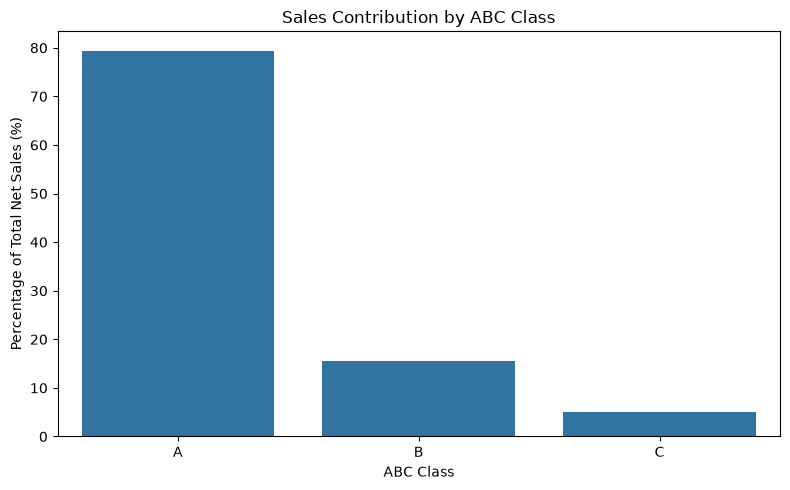

In [13]:
# Visualize sales contribution by ABC class
plt.figure(figsize=(8, 5))

sns.barplot(
    x=abc_summary.index,
    y=abc_summary['sales_contribution_pct']
)

plt.title('Sales Contribution by ABC Class')
plt.xlabel('ABC Class')
plt.ylabel('Percentage of Total Net Sales (%)')

plt.tight_layout()
plt.show()

In [14]:
# Calculate total monthly units sold for each SKU
monthly_sku_sales = (
    df.groupby([
        'sku_id',
        pd.Grouper(key='date', freq='MS')
    ])['units_sold']
    .sum()
    .reset_index()
)

# Display the first 10 rows
monthly_sku_sales.head(10)

,sku_id,date,units_sold
0,SKU0001,2021-01-01,49190
1,SKU0001,2021-02-01,42362
2,SKU0001,2021-03-01,47504
3,SKU0001,2021-04-01,43922
4,SKU0001,2021-05-01,50141
5,SKU0001,2021-06-01,60077
6,SKU0001,2021-07-01,63525
7,SKU0001,2021-08-01,70848
8,SKU0001,2021-09-01,41533
9,SKU0001,2021-10-01,43840


In [15]:
# Count the number of months recorded for each SKU
sku_month_counts = (
    monthly_sku_sales.groupby('sku_id')['date']
    .nunique()
)

# Check the distribution of month counts
sku_month_counts.value_counts().sort_index()

date
36    102
Name: count, dtype: int64

In [16]:
# Count monthly observations with zero sales
zero_sales_months = (
    monthly_sku_sales['units_sold'] == 0
).sum()

print("Monthly observations with zero sales:", zero_sales_months)

Monthly observations with zero sales: 0


In [17]:
# Calculate monthly demand statistics for each SKU
sku_variability = (
    monthly_sku_sales.groupby('sku_id')
    .agg(
        mean_monthly_sales=('units_sold', 'mean'),
        std_monthly_sales=('units_sold', 'std')
    )
    .reset_index()
)

In [18]:
# Calculate coefficient of variation

sku_variability['CV'] = (
    sku_variability['std_monthly_sales']
    / sku_variability['mean_monthly_sales']
)
# Display the first 10 SKUs
sku_variability.head(10)

,sku_id,mean_monthly_sales,std_monthly_sales,CV
0,SKU0001,49788.361111,9780.078858,0.196433
1,SKU0002,21297.750000,4266.228287,0.200314
2,SKU0003,7010.444444,1374.256463,0.196030
3,SKU0004,30526.333333,6056.692888,0.198409
4,SKU0005,30458.333333,6560.331803,0.215387
5,SKU0006,46171.527778,9517.412105,0.206132
6,SKU0007,9430.916667,1866.006146,0.197861
7,SKU0008,7708.944444,1554.683136,0.201673
8,SKU0009,20525.222222,4025.791124,0.196139
9,SKU0010,12581.472222,2758.774919,0.219273


In [19]:
# Summarize coefficient of variation
sku_variability['CV'].describe()

count    102.000000
mean       0.107071
std        0.072538
min        0.029348
25%        0.037405
50%        0.076353
75%        0.197504
max        0.241876
Name: CV, dtype: float64

In [20]:
# Calculate dataset-specific CV thresholds

q1 = sku_variability['CV'].quantile(0.25)
q3 = sku_variability['CV'].quantile(0.75)

# Classify products by demand variability
sku_variability['XYZ_class'] = np.select(
    [
        sku_variability['CV'] <= q1,
        sku_variability['CV'] <= q3
    ],
    [
        'X',
        'Y'
    ],
    default='Z'
)

# Count SKUs in each XYZ class
xyz_counts = (
    sku_variability['XYZ_class']
    .value_counts()
    .reindex(['X', 'Y', 'Z'], fill_value=0)
)

print(xyz_counts)

XYZ_class
X    26
Y    50
Z    26
Name: count, dtype: int64


# XYZ Analysis: Key Findings
XYZ analysis groups products based on how much their sales change over time.

We used the coefficient of variation (CV) to measure these changes.

X: Products with the most stable monthly sales.
Y: Products with moderately changing monthly sales.
Z: Products with the most changing monthly sales.

Out of 102 products:

26 products belong to Group X.
50 products belong to Group Y.
26 products belong to Group Z.

We used the 25th and 75th percentiles of CV to divide the products into groups.

What does this mean?

Most products have relatively stable monthly sales, although some change more than others.

Why is this important?

XYZ analysis helps businesses understand which products have more consistent sales and which may need closer monitoring.

Conclusion: XYZ analysis helps us compare sales stability across products and supports better inventory planning.



In [21]:
# Combine ABC and XYZ classifications
abc_xyz = sku_sales.merge(
    sku_variability[['sku_id', 'CV', 'XYZ_class']],
    on='sku_id',
    how='inner'
)

# Create combined classification
abc_xyz['ABC_XYZ_class'] = (
    abc_xyz['ABC_class'] + abc_xyz['XYZ_class']
)

# Display the first 10 products
abc_xyz.head(10)

,sku_id,total_units_sold,total_net_sales,sales_percentage,cumulative_percentage,ABC_class,CV,XYZ_class,ABC_XYZ_class
0,SKU0018,1173032,17032424.64,3.601343,3.601343,A,0.205338,Z,AZ
1,SKU0027,1200897,16000295.02,3.383109,6.984452,A,0.099845,Y,AY
2,SKU0026,893989,13025419.73,2.754100,9.738553,A,0.110808,Y,AY
3,SKU0099,1242389,12968809.43,2.742131,12.480683,A,0.077693,Y,AY
4,SKU0092,895842,12496995.90,2.642370,15.123053,A,0.039920,Y,AY
5,SKU0100,920354,12351150.68,2.611533,17.734586,A,0.031467,X,AX
6,SKU0064,990120,12326994.00,2.606425,20.341011,A,0.033535,X,AX
7,SKU0061,972948,11967260.40,2.530363,22.871374,A,0.031430,X,AX
8,SKU0028,1253907,11749108.59,2.484237,25.355610,A,0.117090,Y,AY
9,SKU0097,851911,11594508.71,2.451548,27.807158,A,0.029348,X,AX


In [22]:
# Count SKUs in each ABC-XYZ combination
abc_xyz_matrix = pd.crosstab(
    abc_xyz['ABC_class'],
    abc_xyz['XYZ_class']
)

# Arrange categories in the correct order
abc_xyz_matrix = abc_xyz_matrix.reindex(
    index=['A', 'B', 'C'],
    columns=['X', 'Y', 'Z'],
    fill_value=0
)
abc_xyz_matrix

XYZ_class,X,Y,Z
ABC_class,,,
A,15,23,11
B,5,14,10
C,6,13,5


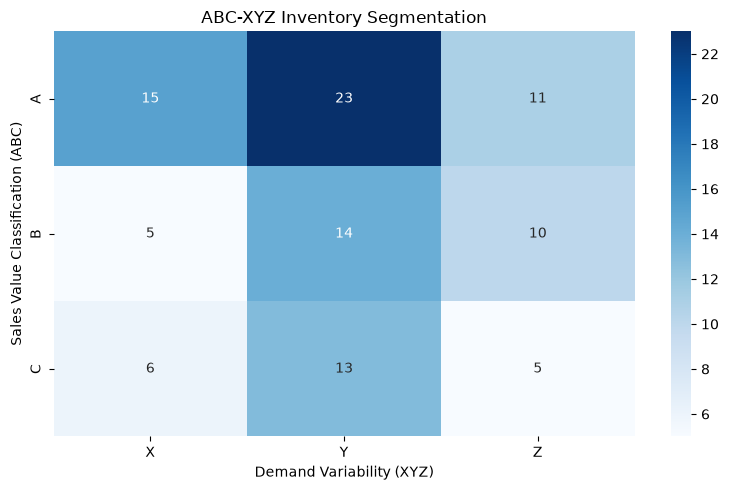

In [23]:
# Visualize ABC-XYZ segmentation

plt.figure(figsize=(8, 5))
sns.heatmap(
    abc_xyz_matrix,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('ABC-XYZ Inventory Segmentation')
plt.xlabel('Demand Variability (XYZ)')
plt.ylabel('Sales Value Classification (ABC)')

plt.tight_layout()
plt.show()

ABC-XYZ Analysis: Key Findings

What is ABC-XYZ analysis?

It combines two methods:

ABC: Shows which products bring in the most sales value.
XYZ: Shows how much product sales change from month to month.

Our findings:

AX: 15 products have high sales value and relatively stable sales.
AY: 23 products have high sales value and moderate sales changes.
AZ: 11 products have high sales value and relatively greater sales changes.

AY is the largest group, with 23 products.

The 11 AZ products may need closer stock monitoring because they generate high sales value but have more variable monthly sales.


This is important because, Businesses can use these groups to decide which products need closer monitoring and more careful stock planning.

Conclusion:ABC-XYZ analysis helps businesses manage inventory by considering both sales value and sales stability.
